# 🏛️ UNIVERSIDAD NACIONAL DE SAN ANTONIO ABAD DEL CUSCO
### Facultad de Ingeniería Civil — Laboratorio de Materiales y Concreto
**Asignatura:** Tecnología del Concreto (IC152)  
**Docente:** ______________________________ | **Grupo / Brigada:** ______________________________  
**Semestre:** 2026-II  

---

# 🔬 PRÁCTICA N.° 4 (TC-04): Análisis Granulométrico de Agregados Fino y Grueso
### Cuaderno Interactivo de Procesamiento y Control Normativo

> **Normativa Técnica Aplicable:**  
> **NTP 400.012:2021** | **ASTM C136-19** | **NTP 400.037:2025 (Tablas 1 y 3) / ASTM C33/C33M-24 (Tabla 3)** | **ASTM E11-24**

---

### 🎯 Objetivos de la Práctica
1. Calcular la gradación completa (% Retenido, % Ret. Acum., % Que Pasa) consolidando los finos lavados de TC-03.
2. Verificar el error de pérdida en tamizado seco (<= 0,3 % según ASTM C136 num. 8.7) y el paso N.° 200.
3. Calcular Módulo de Finura (MF), Tamaño Máximo (TM), TMN, D10, D30, D60, Cu y Cc.
4. Comprender, seleccionar y justificar técnicamente el **huso granulométrico adecuado** según el TMN y la obra, contrastando contra los **15 husos normalizados**.

## ⚙️ 1. Conexión con el Motor de Cálculo (`civillab_unsaac`)
Presiona **Ejecutar (▶)** en la siguiente celda antes de comenzar. Conecta las fórmulas normativas de la UNSAAC, tablas y graficadores.

In [1]:
# ==============================================================================
# CONEXIÓN CON LA LIBRERÍA DEL LABORATORIO (Ejecutar primero, no modificar)
# ==============================================================================
try:
    import civillab_unsaac as lab
except ModuleNotFoundError:
    # Si la librería aún no está instalada, la ubicamos automáticamente en el proyecto
    import sys
    from pathlib import Path
    raices = [
        Path.cwd(),
        *list(Path.cwd().parents)[:3],
        Path.cwd() / "08_SOFTWARE_LABORATORIO",
        Path.cwd() / "0003_UNSAAC_DOCENCIA" / "08_SOFTWARE_LABORATORIO",
    ]
    for r in raices:
        if (r / "civillab_unsaac").is_dir():
            sys.path.insert(0, str(r))
            break
    import civillab_unsaac as lab

from pathlib import Path
from civillab_unsaac import *
import matplotlib
try:
    get_ipython()
except NameError:
    matplotlib.use("Agg")

import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

try:
    from IPython.display import display
except ImportError:
    display = print

# Carpeta limpia para gráficos y fichas Excel de salida
_pkg_root = Path(lab.__file__).resolve().parents[1]
DIR_SALIDA = (_pkg_root / "fichas_generadas") if (_pkg_root / "notebooks").is_dir() else (Path.cwd() / "fichas_generadas")
DIR_SALIDA.mkdir(parents=True, exist_ok=True)

print("✓ Suite CivilLab UNSAAC conectada y lista para calcular.")

✓ Suite CivilLab UNSAAC conectada y lista para calcular.


---
## 📚 1. ¿Qué es un Huso Granulométrico y Cuáles Existen?
Un **huso granulométrico** es la banda de porcentajes acumulados que pasan (límite mínimo y máximo tamiz por tamiz) dentro de la cual debe caer la curva del agregado para asegurar buena compacidad, trabajabilidad y economía de pasta en el concreto:

* **Agregado fino (arena):** la norma fija **un único huso** (`NTP 400.037:2025 Tabla 1` / `ASTM C33 num. 6.1`). Adicionalmente, el módulo de fineza **MF** debe ubicarse entre **2,30 y 3,10** (variación máxima ±0,20 en entregas sucesivas de la misma cantera) y **ningún tamiz debe retener más de 45 %** del retenido entre dos mallas consecutivas. Las arenas próximas a los límites mínimos en N.° 50 y N.° 100 pueden dificultar el bombeo, la trabajabilidad o aumentar la exudación.
* **Agregado grueso (piedra chancada / grava):** la `NTP 400.037:2025 Tabla 3` / `ASTM C33 Tabla 3` define **15 husos normalizados** (`'1'` al `'9'`), agrupados en:
  * **Husos de tamaño grande (`1`, `2`, `3`, `357`, `4`, `467`):** concreto masivo, presas, obras hidráulicas y grandes cimentaciones. *(Nota 11 ASTM C33: los husos **357** y **467** abarcan rangos amplios y deberían entregarse en al menos dos tamaños separados para evitar segregación).*
  * **Husos de edificación y obras corrientes (`5`, `56`, `57`, `6`, `67`, `7`, `8`, `89`, `9`):** zapatas, vigas, columnas, losas, placas, prefabricados y grout.
  * **Límite de finos N.° 200 (Nota B):** en todos los husos del grueso, el material que pasa la malla **N.° 200 (75 µm)** no debe exceder **1,0 %** (hasta **1,5 %** solo si está esencialmente libre de arcilla o pizarra).
  * **Nota A (Huso 9):** técnicamente es un agregado fino según terminología ASTM, pero se emplea como grueso al combinarse con el **Huso 8** para formar el **Huso 89**.

In [2]:
# Despliega el catálogo maestro de los 15 husos normalizados con TMN, uso en obra y notas normativas:
display(catalogo_husos_df())

,Huso N.°,TMN Asociado,Tamaño Nominal,Tipo de Banda,Uso Recomendado en Obra,Nota Normativa (ASTM C33 / NTP 400.037)
0,1,"3 1/2"" (90.0 mm)","90 a 37,5 mm (3 1/2"" a 1 1/2"")",Tamaño grande (masivo),"Concreto masivo (presas, grandes cimentaciones)","Nota B: N° 200 <= 1,0 % (1,5 % sin arcilla/piz..."
1,2,"2 1/2"" (63.0 mm)","63 a 37,5 mm (2 1/2"" a 1 1/2"")",Tamaño grande (masivo),Concreto masivo / obras hidráulicas,"Nota B: N° 200 <= 1,0 % (1,5 % sin arcilla/piz..."
2,3,"2"" (50.0 mm)","50 a 25,0 mm (2"" a 1"")",Fracción gruesa cerrada,Cimentaciones masivas y obras viales gruesas,"Nota B: N° 200 <= 1,0 % (1,5 % sin arcilla/piz..."
3,357,"2"" (50.0 mm)","50 a 4,75 mm (2"" a N° 4)",Gradación amplia (hasta N° 4),Concreto ciclópeo o cimentaciones de gran volumen,Nota 11: entregar en al menos 2 tamaños separados
4,4,"1 1/2"" (37.5 mm)","37,5 a 19,0 mm (1 1/2"" a 3/4"")",Fracción gruesa cerrada,Presas y elementos con poco acero,Se puede combinar con gravilla si falta finos
5,467,"1 1/2"" (37.5 mm)","37,5 a 4,75 mm (1 1/2"" a N° 4)",Gradación continua (hasta N° 4),"Zapatas amplias, muros de contención y pavimen...",Nota 11: entregar en al menos 2 tamaños separados
6,5,"1"" (25.0 mm)","25,0 a 12,5 mm (1"" a 1/2"")","Fracción única (1"" a 1/2"")",Grava clasificada para dosificación combinada,Menor continuidad granulométrica que el Huso 57
7,56,"1"" (25.0 mm)","25,0 a 9,5 mm (1"" a 3/8"")","Gradación intermedia (1"" a 3/8"")",Fracción gruesa intermedia,"Alternativa al 57 sin fracción entre 3/8"" y N° 4"
8,57,"1"" (25.0 mm)","25,0 a 4,75 mm (1"" a N° 4)",Gradación continua (hasta N° 4),"Uso común en zapatas, vigas anchas y losas mac...","Preferido para TMN 1"" en concreto estructural"
9,6,"3/4"" (19.0 mm)","19,0 a 9,5 mm (3/4"" a 3/8"")","Fracción única (3/4"" a 3/8"")",Fracción para combinar con gravilla,"Alternativa si falta fracción 3/8"" a N° 4"


---
## 🎯 2. ¿Cómo Elegir el Huso Correcto en Obra y en Laboratorio?

La elección del huso del agregado grueso responde a **tres pasos técnicos**:

1. **Restricción constructiva de obra (RNE E.060 / ACI 318):** antes de mirar la cantera, el **TMN máximo permisible** de la piedra no debe superar `1/5` de la menor dimensión entre encofrados, `1/3` del espesor de losas ni `3/4` del espaciamiento libre entre barras de acero.
2. **Mapeo por Tamaño Máximo Nominal (TMN):** una vez definido o medido el TMN de la piedra, se selecciona entre los husos que le corresponden:

| TMN del agregado grueso | Husos correspondientes | Criterio práctico de selección |
| :--- | :--- | :--- |
| **3 1/2"** (90,0 mm) · **2 1/2"** (63,0 mm) | **`1`** · **`2`** | Exclusivos de concreto masivo y obras hidráulicas |
| **2"** (50,0 mm) · **1 1/2"** (37,5 mm) | **`3`** / **`357`** · **`4`** / **`467`** | Cimentaciones masivas, pavimentos y concreto ciclópeo (`357`/`467` en 2 fracciones) |
| **1"** (25,0 mm) | **`5`**, **`56`** o **`57`** | **`57`** es el estándar continuo para zapatas, losas macizas y vigas anchas |
| **3/4"** (19,0 mm) | **`6`** o **`67`** | **`67`** es el **más usado en edificación** (columnas, vigas, aligerados) |
| **1/2"** (12,5 mm) | **`7`** | Placas delgadas, elementos muy armados y prefabricados |
| **3/8"** (9,5 mm) · **N.° 4** (4,75 mm) | **`8`** / **`89`** · **`9`** | Concreto bombeable, microconcreto y *grout* de albañilería armada |

3. **Ventaja de los husos terminados en `7` (`467`, `57`, `67`):** al extender su gradación hasta el tamiz **N.° 4 (4,75 mm)**, generan **curvas más continuas** y mejor empaquetamiento que los husos de fracción cerrada (`4`, `5`, `6`), reduciendo vacíos y consumo de cemento.
4. **¿Qué hacer si la curva no encaja exactamente?** Primero se verifica si cumple otro huso del mismo TMN. Si ninguno cumple al 100 %, la **NTP 400.037:2025** *(num. 6.3 y Nota 11)* permite usar el agregado **solo si existen estudios y diseños de mezcla** que garanticen la resistencia, trabajabilidad y durabilidad exigidas.

La siguiente gráfica compara visualmente los tres husos más usados en edificación (**57**, **67** y **7**):

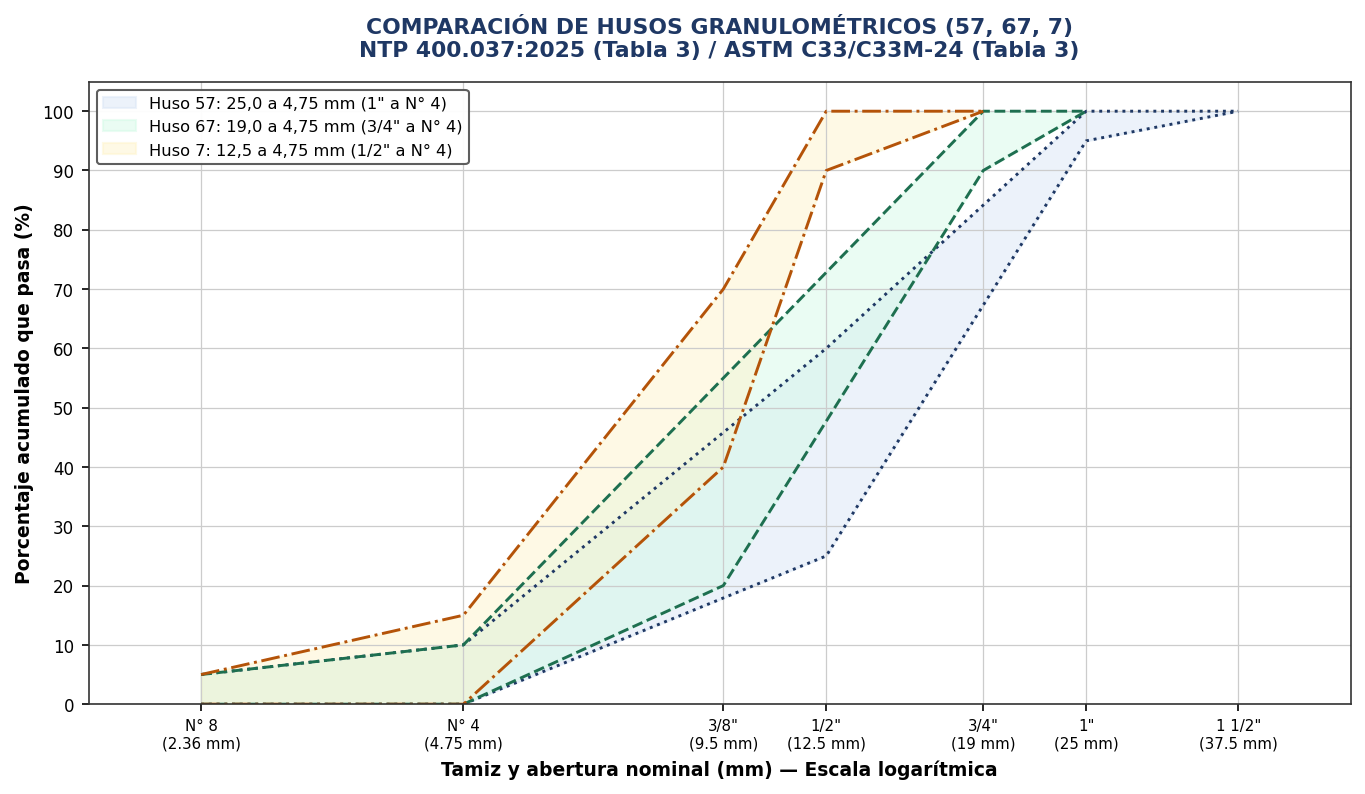

In [3]:
# Visualiza cómo cambian las bandas normadas para TMN 1" (Huso 57), 3/4" (Huso 67) y 1/2" (Huso 7):
graficar_comparacion_husos(
    husos=["57", "67", "7"],
    guardar_ruta=DIR_SALIDA / "TC-04_Comparacion_Husos_57_67_7.png",
    mostrar=True,
)

---
## 🏜️ PARTE A: Agregado Fino (Arena)
Ingresa las masas de la balanza en un diccionario único `{tamiz: peso_g}` (es imposible desfasar tamices). Si lavaste antes en TC-03, el programa calcula automáticamente cuánto fino pasó por la malla N.° 200 al restar `masa_antes_lavado - masa_despues_lavado`.


=== EVALUACIÓN NORMATIVA — GRANULOMETRÍA (FINO) ===
Cantera / Procedencia: Cantera en estudio (Arena) | Muestra: TC-B-AF-01 | Fecha: 2026-11-11
Masa seca inicial: 500.0 g | Fino lavado malla N° 200: 12.0 g (2.4%)
Control de pérdida en tamizado seco: 0.00 % (Límite ASTM C136 num. 8.7 <= 0,3 %): CONFORME

PARÁMETROS FÍSICOS CALCULADOS:
• Módulo de Finura (MF): 2.75
  -> Criterio MF ASTM C33 (2,30 a 3,10): CONFORME
• Máximo retenido entre tamices consecutivos: 24.0 % (N° 16 - N° 30)
  -> Criterio ASTM C33 num. 6.2 (<= 45 %): CONFORME
• Diámetros característicos: D10 = 0.166 mm | D30 = 0.386 mm | D60 = 0.942 mm
• Coeficientes de gradación: Cu = 5.67 | Cc = 0.95

EVALUACIÓN DEL HUSO GRANULOMÉTRICO:
[CONFORME] La muestra CUMPLE íntegramente las tolerancias del Huso Único (Tabla 1 NTP 400.037:2025).


,Tamiz,Abertura (mm),Retenido (g),% Retenido,% Ret. Acum.,% Pasa,Huso Norma
0,"3/8""",9.500,0.0,0.0%,0.0%,100.0%,100%
1,N° 4,4.750,15.0,3.0%,3.0%,97.0%,95% - 100%
2,N° 8,2.360,55.0,11.0%,14.0%,86.0%,80% - 100%
3,N° 16,1.180,90.0,18.0%,32.0%,68.0%,50% - 85%
4,N° 30,0.600,120.0,24.0%,56.0%,44.0%,25% - 60%
5,N° 50,0.300,110.0,22.0%,78.0%,22.0%,5% - 30%
6,N° 100,0.150,70.0,14.0%,92.0%,8.0%,0% - 10%
7,Fondo,—,28.0,8.0%,100.0%,0.0%,—


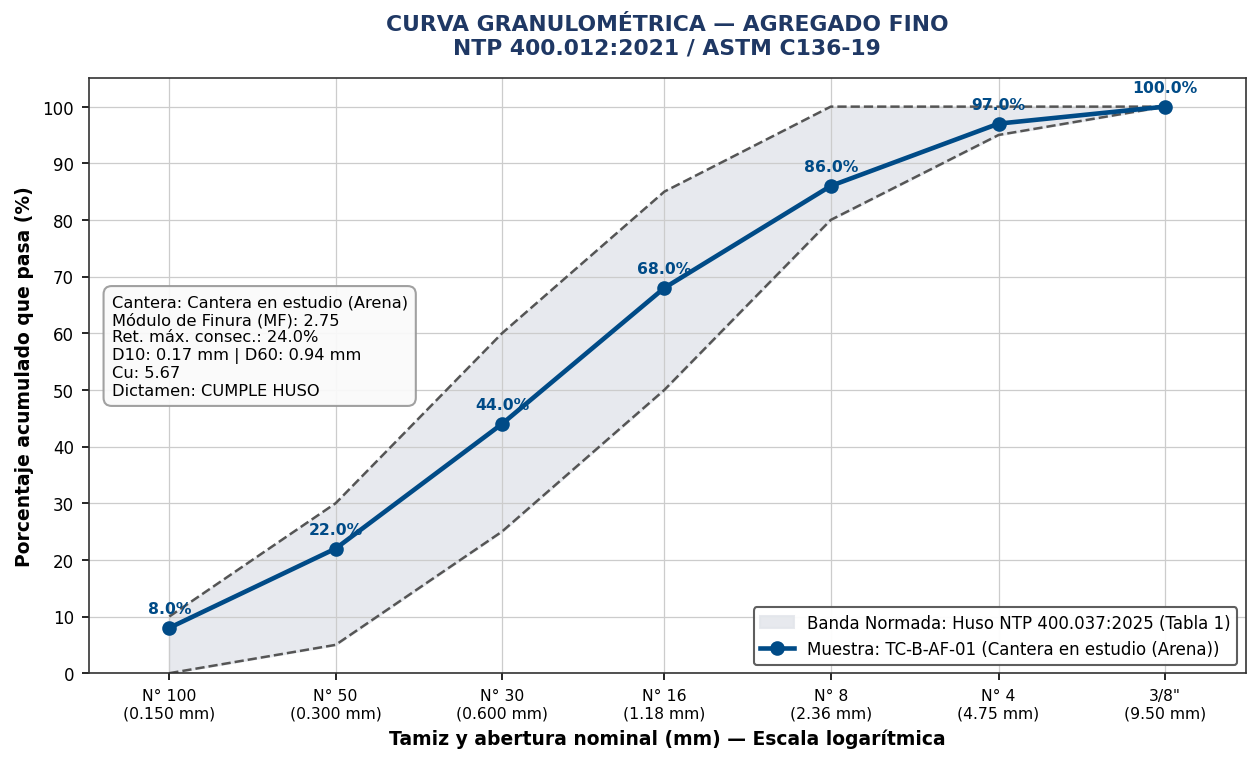

In [4]:
# 1. Datos de muestra lavada (Si no se lavó antes, pon igual ambos pesos)
peso_seco_antes_lavado_fino = 500.0
peso_seco_despues_lavado_fino = 488.0   # El programa resta 500 - 488 = 12 g automáticos

# 2. Lecturas de balanza tras tamizado en seco (g)
lecturas_fino = {
    '3/8"'  : 0.0,
    'N° 4'  : 15.0,
    'N° 8'  : 55.0,
    'N° 16' : 90.0,
    'N° 30' : 120.0,
    'N° 50' : 110.0,
    'N° 100': 70.0,
    'Fondo' : 28.0,
}

gfino = Granulometria(
    tipo="fino",
    lecturas_balanza=lecturas_fino,
    masa_seca_inicial=peso_seco_antes_lavado_fino,
    masa_lavada=peso_seco_despues_lavado_fino,
    cantera="Cantera en estudio (Arena)",
    muestra_id="TC-B-AF-01",
)

display(gfino.tabla_resumen())
print("\n" + gfino.diagnostico_tecnico())
graficar_granulometria(gfino, guardar_ruta=DIR_SALIDA / "TC-04_Curva_Agregado_Fino.png", mostrar=True)

---
## 🪨 PARTE B: Agregado Grueso (Piedra / Grava) y Selector Automático de Huso
Puedes usar **`huso_seleccionado = "auto"`** para que el programa determine tu TMN, elija el huso normado más adecuado y justifique el porqué; o bien escribir un huso específico (ej. `"67"`, `"57"`, `"7"`, `"467"`, etc.) cuando quieras contrastar contra una especificación fija de expediente técnico. Luego, `tabla_comparacion_husos()` audita tu muestra contra **los 15 husos** simultáneamente.


=== EVALUACIÓN NORMATIVA — GRANULOMETRÍA (GRUESO) ===
Cantera / Procedencia: Cantera en estudio (Piedra Chancada) | Muestra: TC-B-AG-01 | Fecha: 2026-11-11
Masa seca inicial: 5000.0 g | Fino lavado malla N° 200: 0.0 g (0.0%)
Control de pérdida en tamizado seco: 0.00 % (Límite ASTM C136 num. 8.7 <= 0,3 %): CONFORME

PARÁMETROS FÍSICOS CALCULADOS:
• Módulo de Finura (MF): 6.70
• Tamaño Máximo (TM): 1"
• Tamaño Máximo Nominal (TMN): 3/4"
• Huso evaluado (Automático por TMN): Huso N.° 67 (19,0 a 4,75 mm (3/4" a N° 4)) [NTP 400.037 / ASTM C33]
  -> Uso típico en obra: Estándar en edificación (columnas, vigas, aligerados)
  -> Criterio de selección: TMN detectado = 3/4" -> corresponde a huso(s) 67, 6. Se recomienda Huso 67 (Estándar en edificación (columnas, vigas, aligerados)) porque cumple íntegramente la banda y prioriza gradación continua.
  -> Nota normativa: Estándar más usado en edificación armada
• Diámetros característicos: D10 = 5.708 mm | D30 = 9.556 mm | D60 = 12.873 mm
• Coefic

,Tamiz,Abertura (mm),Retenido (g),% Retenido,% Ret. Acum.,% Pasa,Huso Norma
0,"1 1/2""",37.500,0.0,0.0%,0.0%,100.0%,—
1,"1""",25.000,0.0,0.0%,0.0%,100.0%,100%
2,"3/4""",19.000,280.0,5.6%,5.6%,94.4%,90% - 100%
3,"1/2""",12.500,1850.0,37.0%,42.6%,57.4%,—
4,"3/8""",9.500,1400.0,28.0%,70.6%,29.4%,20% - 55%
5,N° 4,4.750,1320.0,26.4%,97.0%,3.0%,0% - 10%
6,N° 8,2.360,115.0,2.3%,99.3%,0.7%,0% - 5%
7,Fondo,—,35.0,0.7%,100.0%,0.0%,—


,Huso N.°,TMN Esperado,Coincide TMN,Cumple Banda,Desv. Máx. (%),Tamices Observados,Uso Recomendado en Obra
0,67,"3/4""",Sí,CUMPLE,0.0,—,"Estándar en edificación (columnas, vigas, alig..."
1,57,"1""",No,CUMPLE,0.0,—,"Uso común en zapatas, vigas anchas y losas mac..."
2,6,"3/4""",Sí,NO CUMPLE,14.4,"1/2"": 57.4% (> 55%); 3/8"": 29.4% (> 15%)","Fracción para combinar con gravilla [19,0 a 9,..."
3,56,"1""",No,NO CUMPLE,17.4,"3/4"": 94.4% (> 85%); 1/2"": 57.4% (> 40%); 3/8""...","Fracción gruesa intermedia [25,0 a 9,5 mm (1"" ..."
4,467,"1 1/2""",No,NO CUMPLE,24.4,"3/4"": 94.4% (> 70%)","Zapatas amplias, muros de contención y pavimen..."
5,357,"2""",No,NO CUMPLE,30.0,"1"": 100.0% (> 70%); 1/2"": 57.4% (> 30%)",Concreto ciclópeo o cimentaciones de gran volu...
6,7,"1/2""",No,NO CUMPLE,32.6,"3/4"": 94.4% (< 100%); 1/2"": 57.4% (< 90%); 3/8...","Placas delgadas, elementos esbeltos y prefabri..."
7,5,"1""",No,NO CUMPLE,47.4,"3/4"": 94.4% (> 55%); 1/2"": 57.4% (> 10%); 3/8""...",Grava clasificada para dosificación combinada ...
8,8,"3/8""",No,NO CUMPLE,55.6,"1/2"": 57.4% (< 100%); 3/8"": 29.4% (< 85%); N° ...",Concreto bombeable o relleno de albañilería ar...
9,89,"3/8""",No,NO CUMPLE,60.6,"1/2"": 57.4% (< 100%); 3/8"": 29.4% (< 90%); N° ...","Microconcreto y concretos de alta fluidez [9,5..."


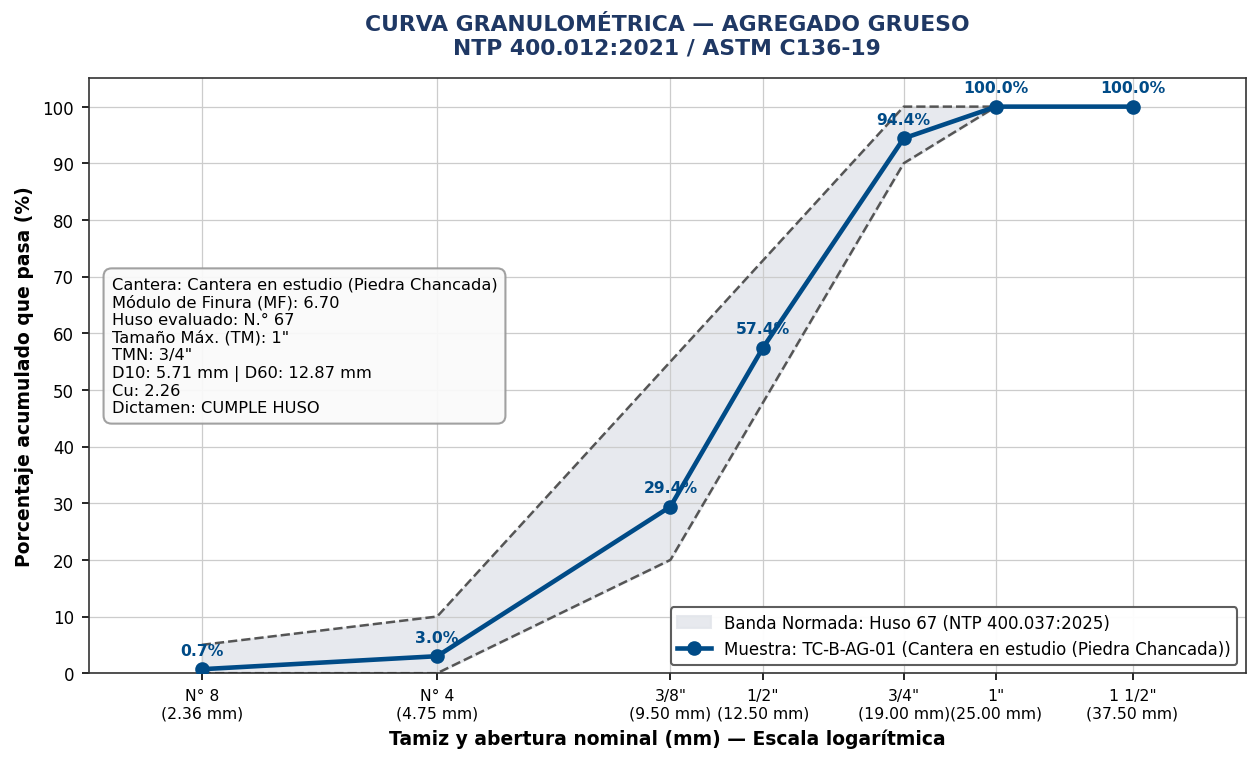

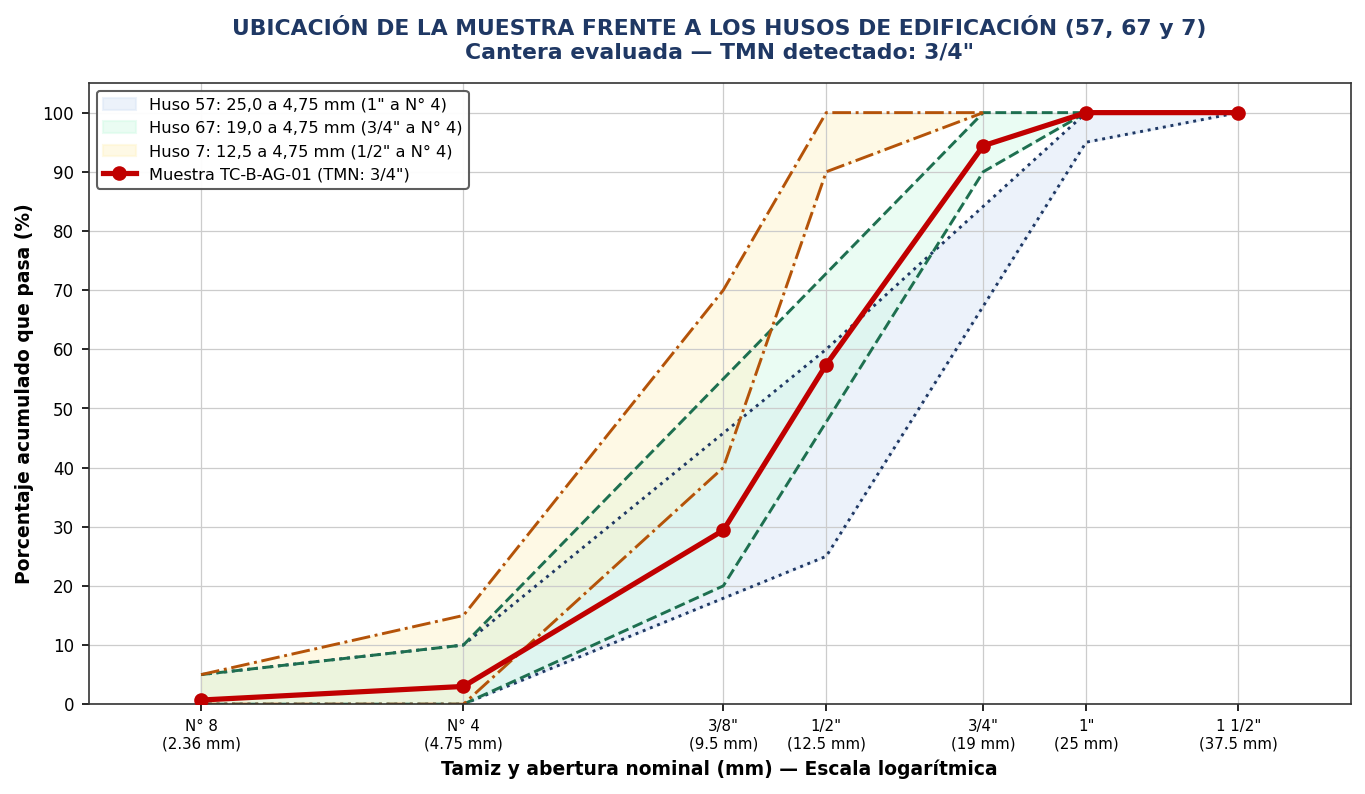

In [5]:
# Usa "auto" para selección inteligente según TMN/curva, o fija un huso ('1'..'9'):
huso_seleccionado = "auto"

lecturas_grueso = {
    '1 1/2"': 0.0,
    '1"'    : 0.0,
    '3/4"'  : 280.0,
    '1/2"'  : 1850.0,
    '3/8"'  : 1400.0,
    'N° 4'  : 1320.0,
    'N° 8'  : 115.0,
    'Fondo' : 35.0,
}

ggrueso = Granulometria(
    tipo="grueso",
    lecturas_balanza=lecturas_grueso,
    huso=huso_seleccionado,
    cantera="Cantera en estudio (Piedra Chancada)",
    muestra_id="TC-B-AG-01",
)

display(ggrueso.tabla_resumen())
print("\n" + ggrueso.diagnostico_tecnico())

print("\n--- AUDITORÍA DE LA MUESTRA CONTRA TODOS LOS 15 HUSOS (ASTM C33 / NTP 400.037) ---")
display(ggrueso.tabla_comparacion_husos())

graficar_granulometria(ggrueso, guardar_ruta=DIR_SALIDA / "TC-04_Curva_Agregado_Grueso.png", mostrar=True)
graficar_comparacion_husos(
    husos=["57", "67", "7"],
    granulometria=ggrueso,
    titulo=f"UBICACIÓN DE LA MUESTRA FRENTE A LOS HUSOS DE EDIFICACIÓN (57, 67 y 7)\nCantera evaluada — TMN detectado: {ggrueso.tamano_maximo_nominal}",
    guardar_ruta=DIR_SALIDA / "TC-04_Muestra_vs_Husos.png",
    mostrar=True,
)

---
## 📑 PARTE C: Emisión Automática de Fichas Oficiales en Excel (.xlsx)

[OK] Ficha Excel Fino generada:   E:\00_OFI_PRESUPUESTOS_progra\00_PLANES\0003_UNSAAC_DOCENCIA\0003_UNSAAC_DOCENCIA\08_SOFTWARE_LABORATORIO\fichas_generadas\TC-04_Ficha_Agregado_Fino.xlsx
[OK] Ficha Excel Grueso generada: E:\00_OFI_PRESUPUESTOS_progra\00_PLANES\0003_UNSAAC_DOCENCIA\0003_UNSAAC_DOCENCIA\08_SOFTWARE_LABORATORIO\fichas_generadas\TC-04_Ficha_Agregado_Grueso.xlsx


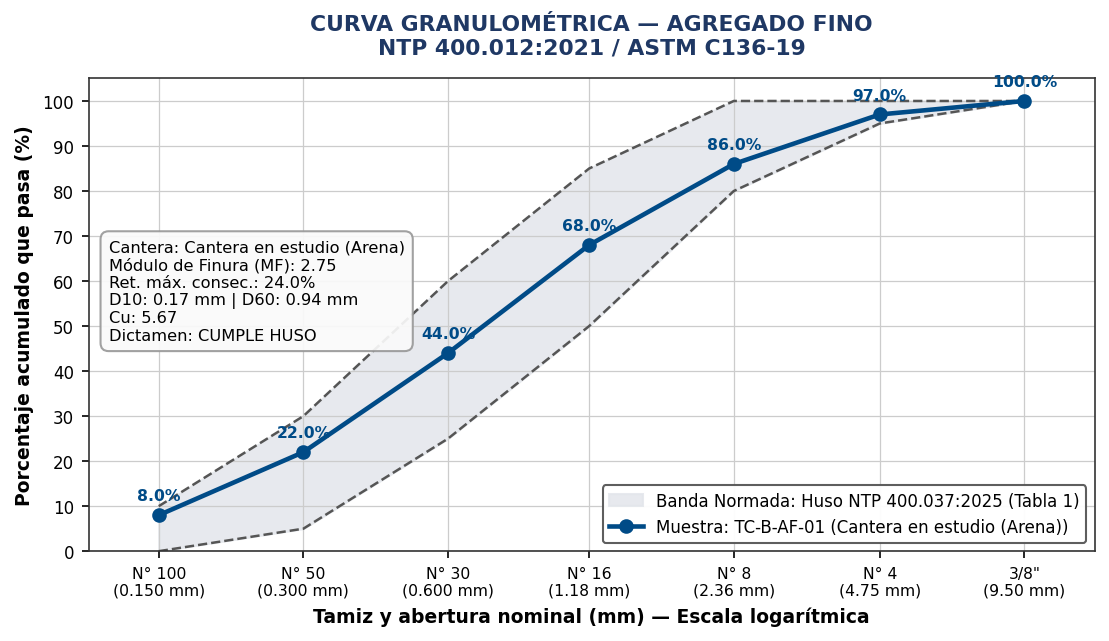

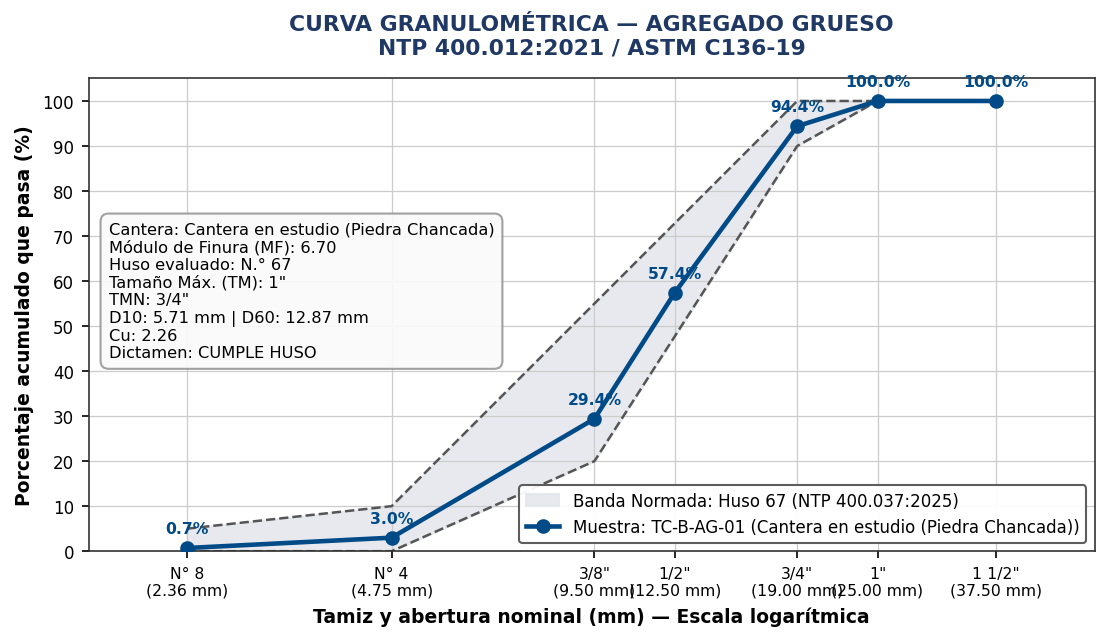

In [6]:
ruta_af = exportar_ficha_granulometria_excel(gfino, DIR_SALIDA / "TC-04_Ficha_Agregado_Fino.xlsx", grupo="Brigada TC")
ruta_ag = exportar_ficha_granulometria_excel(ggrueso, DIR_SALIDA / "TC-04_Ficha_Agregado_Grueso.xlsx", grupo="Brigada TC")
print(f"[OK] Ficha Excel Fino generada:   {ruta_af}")
print(f"[OK] Ficha Excel Grueso generada: {ruta_ag}")